# UTS KLASIFIKASI

## BUSINESS UNDERSTANDING

Proyek klasifikasi tutupan lahan (Land Use Land Cover) wilayah Jawa Timur ini dikembangkan untuk merespons tingginya dinamika alih fungsi lahan akibat urbanisasi dan pertumbuhan ekonomi. Mengingat pemantauan manual di lapangan sangat tidak efisien, sistem ini memanfaatkan citra satelit Sentinel-2 untuk memetakan permukaan bumi secara otomatis, cepat, dan berkala.

Dengan mengekstrak nilai spektral dari Band 4 (Red), Band 8A (Narrow NIR), dan Band 11 (SWIR), model Machine Learning yang dibangun mampu mengatasi kebingungan visual pada citra standar. Sistem dapat membedakan secara presisi objek-objek yang sering kali mengecoh mata manusia, seperti memisahkan hutan daratan dengan hutan mangrove pesisir, atau lahan pertanian produktif dengan area terbangun (build-up area).

Hasil akhir dari prediksi model ini disajikan dalam bentuk dashboard peta interaktif. Melalui platform ini, para pengambil kebijakan dapat langsung memfilter dan memantau distribusi lahan secara real-time demi mendukung perencanaan tata ruang serta pelestarian lingkungan yang lebih akurat.


## DATA UNDERSTANDING

Tahap Data Understanding bertujuan untuk memahami karakteristik, distribusi, dan rincian data spektral yang diekstrak, serta mengidentifikasi potensi masalah pada data sebelum masuk ke tahap pemodelan.

Proses Akuisisi dan Penyiapan Data...
Data lokal belum lengkap. Menginisialisasi Google Earth Engine...
Earth Engine berhasil terhubung.

Membaca file poligon acuan 'UTS_data.geojson'...
Berhasil memuat 251 poligon sampel ke server.

Mengekstrak data latih ke 'dataset_training.csv'...
Data latih CSV berhasil disimpan.

Analisis Eksplorasi Data (Data Understanding)...
Struktur Dataset:
Total baris data (piksel) : 4231
Total kolom              : 6 (1 label 'Class', 5 fitur spektral)

Distribusi Kelas:
 - Perairan       : 3789 piksel
 - Hutan          : 383 piksel
 - Hutan Mangrove : 41 piksel
 - Sawah          : 12 piksel
 - Bangunan       : 6 piksel

Samples Data Teratas:


,Class,Band_2,Band_3,Band_4,Band_8A,Band_11
0,Hutan Mangrove,480.541667,671.363636,418.722222,2941.604167,1491.000000
1,Hutan Mangrove,657.545455,912.555556,626.750000,2734.833333,1469.083333
2,Hutan Mangrove,720.470588,939.181818,590.750000,3529.750000,1790.500000
3,Hutan Mangrove,282.080000,462.625000,219.864865,3040.086957,653.684211
4,Hutan Mangrove,602.400000,729.428571,609.333333,1573.750000,525.714286


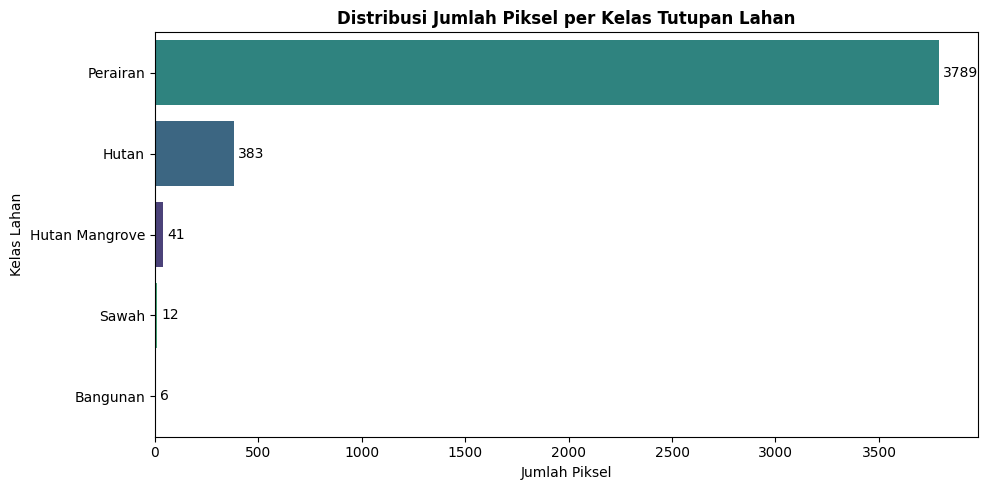

In [3]:
import os
import json
import pandas as pd
import urllib.request
import ee
import geemap
import matplotlib.pyplot as plt
import seaborn as sns

file_csv = 'dataset_training.csv'
file_tif = 'Sentinel2_Area.tif'

print("Proses Akuisisi dan Penyiapan Data...")

if os.path.exists(file_csv) and os.path.exists(file_tif):
    print(f"File '{file_csv}' dan '{file_tif}' ditemukan. Menggunakan data lokal...\n")
else:
    print("Data lokal belum lengkap. Menginisialisasi Google Earth Engine...")
    try:
        ee.Initialize()
    except Exception as e:
        ee.Authenticate()
        ee.Initialize()
    print("Earth Engine berhasil terhubung.\n")

    print("Membaca file poligon acuan 'UTS_data.geojson'...")
    with open('UTS_data.geojson', 'r') as f:
        geojson_data = json.load(f)
        
    pemetaan_kelas = {
        'Hutan Mangrove\n': 'Hutan Mangrove',
        'Hutan biasa (Forest)': 'Hutan',
        'Lautan, danau, perairan ( water body)': 'Perairan',
        'Lahan pertanian ( farm land) ': 'Sawah',
        'Bagunan ( build up) ': 'Bangunan'
    }
    
    fitur_valid = []
    for feature in geojson_data['features']:
        if 'Class' in feature['properties']:
            nama_asli = feature['properties']['Class']
            if nama_asli in pemetaan_kelas:
                feature['properties']['Class'] = pemetaan_kelas[nama_asli]
                fitur_valid.append(feature)
            
    fc = ee.FeatureCollection(fitur_valid)
    print(f"Berhasil memuat {fc.size().getInfo()} poligon sampel ke server.\n")

    # Ekstraksi Data Tabular CSV
    if not os.path.exists(file_csv):
        print(f"Mengekstrak data latih ke '{file_csv}'...")
        
        # PASTIKAN SEMUANYA HURUF BESAR: 'B8A'
        s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
            .filterBounds(fc.geometry()) \
            .filterDate('2025-01-01', '2026-09-30') \
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50)) \
            .median() \
            .select(['B2', 'B3', 'B4', 'B8A', 'B11']) 

        sampled = s2.sampleRegions(
            collection=fc, properties=['Class'], scale=100, tileScale=16, geometries=False
        )

        # PASTIKAN DI SINI JUGA HURUF BESAR: 'B8A'
        url = sampled.getDownloadURL(filetype='csv', selectors=['Class', 'B2', 'B3', 'B4', 'B8A', 'B11'])
        urllib.request.urlretrieve(url, file_csv)
        
        # Penyelarasan nama kolom input dan output
        df_temp = pd.read_csv(file_csv).dropna()
        df_temp = df_temp.rename(columns={
            'B2': 'Band_2', 
            'B3': 'Band_3', 
            'B4': 'Band_4', 
            'B8A': 'Band_8A', # Menyesuaikan B8A
            'B11': 'Band_11'
        })
        df_temp.to_csv(file_csv, index=False)
        print(f"Data latih CSV berhasil disimpan.\n")

    # Ekstraksi Citra Raster TIF (Perbaikan Indentasi Struktural)
    if not os.path.exists(file_tif):
        print(f"File '{file_tif}' tidak ditemukan. Memulai proses unduhan citra untuk inferensi spasial...")
        
        roi = fc.geometry().bounds()
        s2_tif = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
            .filterBounds(roi) \
            .filterDate('2025-01-01', '2026-09-30') \
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
            .median() \
            .select(['B2', 'B3', 'B4', 'B8A', 'B11'])
            
        print("Mengeksekusi proses pengunduhan citra skala spasial 100 meter...")
        geemap.download_ee_image(
            s2_tif, 
            filename=file_tif, 
            scale=100,  
            region=roi,
            crs='EPSG:4326'
        )
        print(f"Unduhan selesai. File raster spasial berhasil disimpan ke '{file_tif}'.\n")


print("Analisis Eksplorasi Data (Data Understanding)...")
df = pd.read_csv(file_csv)

baris, kolom = df.shape
print("Struktur Dataset:")
print(f"Total baris data (piksel) : {baris}")
print(f"Total kolom              : {kolom} (1 label 'Class', {kolom-1} fitur spektral)\n")

print("Distribusi Kelas:")
distribusi = df['Class'].value_counts()
for kelas, jumlah in distribusi.items():
    print(f" - {kelas:<15}: {jumlah} piksel")

print("\nSamples Data Teratas:")
display(df.head())

# Visualisasi Distribusi Data
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

max_width = distribusi.max()
offset = max_width * 0.005 

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + offset, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()



### Sumber Data dan Skenario Ekstraksi

Data tabular diekstrak berdasarkan 251 area Region of Interest (ROI) berformat GeoJSON yang tersebar di wilayah Jawa Timur. Nilai piksel disedot menggunakan Google Earth Engine API (cloud-based) dengan parameter ekstraksi sebagai berikut:

- Koleksi Citra: Sentinel-2 Level-2A (Bottom of Atmosphere).
- Rentang Waktu: 1 Januari 2025 hingga 30 September 2026.
- Toleransi Awan: Maksimum 50%. Reduksi awan dilakukan secara otomatis menggunakan metode Median Reducer (mengambil nilai spektral tengah yang paling bersih dari rentang waktu tersebut).
- Metode Unduh: Data diekstrak melalui URL download menjadi file dataset_training.csv untuk menghindari limitasi memori 5.000 elemen pada server Google.


### Karakteristik Fitur (Spektral Band)

Dataset ini menggunakan 5 variabel (features) independen berupa pantulan cahaya (reflektansi) dari saluran satelit Sentinel-2. Pemilihan band ini bertujuan untuk memisahkan 5 kelas lahan secara optimal:


| Nama Fitur | Fungsi Klasifikasi |
|---|---|
| Band 2 (Blue) & Band 3 (Green) | Sangat sensitif terhadap pantulan air. Kehadiran dua band ini krusial untuk membedakan kelas Perairan dengan objek gelap lain seperti bayangan atau aspal. |
| Band 4 (Red) | Menyerap klorofil tanaman secara kuat. Sangat esensial untuk mendeteksi kerapatan daun dan memisahkan vegetasi dari non-vegetasi. |
| Band 8a (Narrow NIR) | Memiliki rentang gelombang inframerah dekat yang sempit dan presisi. Mampu menembus gangguan aerosol atmosfer lebih baik dari B8 biasa, sehingga sangat akurat untuk membedakan detail vegetasi spesifik (Hutan Mangrove vs Hutan biasa). |
| Band 11 (SWIR) | Sangat sensitif terhadap kelembapan tanah, kandungan air pada kanopi, dan material beton. Menjadi fitur penegas utama untuk mengklasifikasikan area Bangunan dan Sawah kering. |


Struktur Dataset:
Total baris data (piksel) : 4231
Total kolom              : 6 (1 label 'Class', 5 fitur spektral)

Distribusi Kelas:
 - Perairan       : 3789 piksel
 - Hutan          : 383 piksel
 - Hutan Mangrove : 41 piksel
 - Sawah          : 12 piksel
 - Bangunan       : 6 piksel

Samples Data Teratas:


,Class,Band_2,Band_3,Band_4,Band_8A,Band_11
0,Hutan Mangrove,480.541667,671.363636,418.722222,2941.604167,1491.000000
1,Hutan Mangrove,657.545455,912.555556,626.750000,2734.833333,1469.083333
2,Hutan Mangrove,720.470588,939.181818,590.750000,3529.750000,1790.500000
3,Hutan Mangrove,282.080000,462.625000,219.864865,3040.086957,653.684211
4,Hutan Mangrove,602.400000,729.428571,609.333333,1573.750000,525.714286


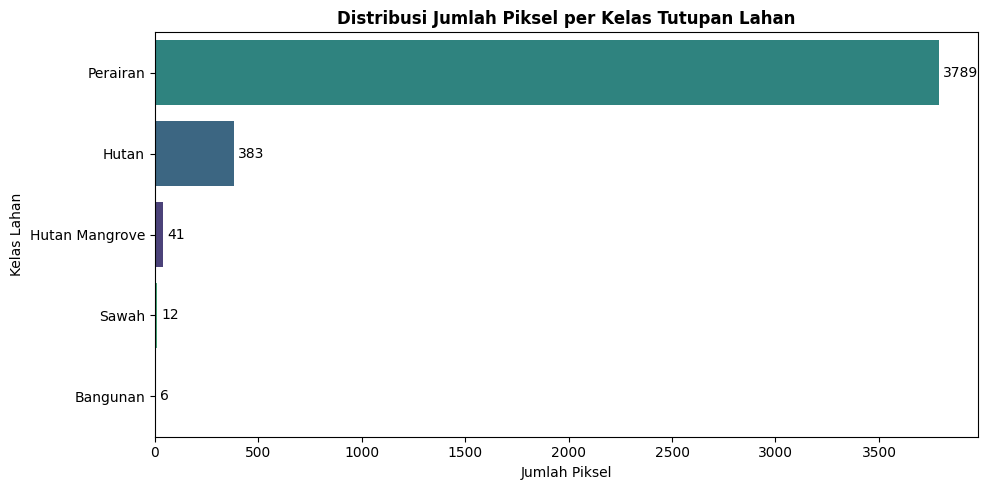

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset_training.csv')

# Informasi Dimensi Dataset
baris, kolom = df.shape
print("Struktur Dataset:")
print(f"Total baris data (piksel) : {baris}")
print(f"Total kolom              : {kolom} (1 label 'Class', {kolom-1} fitur spektral)\n")

# Informasi Distribusi Kelas
print("Distribusi Kelas:")
distribusi = df['Class'].value_counts()
for kelas, jumlah in distribusi.items():
    print(f" - {kelas:<15}: {jumlah} piksel")

print("\nSamples Data Teratas:")
display(df.head())

# Visualisasi Distribusi Kelas
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

# Menampilkan label angka secara dinamis di ujung bar grafik
max_width = distribusi.max()
offset = max_width * 0.005 

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + offset, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()


### Temuan Kritis (Data Issues)
Berdasarkan hasil analisis, dataset ini mengalami masalah Extreme Class Imbalance (ketidakseimbangan kelas yang sangat ekstrem). Kelas Perairan sangat mendominasi dengan 3.789 piksel (sekitar 89,5% dari keseluruhan 4.231 data piksel), sementara kelas minoritas seperti Sawah dan Bangunan masing-masing hanya memiliki 12 piksel (0,28%) dan 6 piksel (0,14%) dari total dataset.

Kondisi data yang sangat timpang dengan jumlah sampel minoritas yang sangat minim ini berisiko tinggi membuat model mengalami bias mayoritas, di mana algoritma akan cenderung mengabaikan pola kelas kecil dan salah memprediksi objek daratan (seperti bangunan atau sawah) sebagai Perairan demi mencapai akurasi semu yang tinggi. Oleh karena itu, tahap Data Preparation berikutnya wajib menerapkan strategi penyeimbangan data melalui metode *undersampling* murni untuk menekan dominasi kelas mayoritas, dipadukan dengan pembobotan kelas dari dalam algoritma (*algorithmic class weighting*) agar model dapat mengenali pola kelas minoritas secara adil tanpa harus melakukan kloning data sintetis yang berisiko *overfitting*.


### Pengecekan Missing Values

Sebelum melangkah ke tahap selanjutnya, perlu dipastikan bahwa seluruh piksel memiliki nilai spektral yang lengkap. Hal ini dilakukan untuk mengidentifikasi adanya data kosong akibat kendala teknis saat perekaman objek, seperti tutupan awan pekat, bayangan awan, atau gangguan pada sensor satelit.

In [5]:
# Memeriksa jumlah data kosong (null/NaN) di setiap kolom
missing_data = df.isnull().sum()
total_missing = missing_data.sum()

print("Jumlah Nilai Kosong per Kolom:")
print(missing_data)
print(f"\nTotal nilai kosong: {total_missing}")

if total_missing == 0:
    print("Dataset bersih dari nilai kosong.")
else:
    print(f"Peringatan: Ditemukan {total_missing} nilai kosong yang perlu ditangani.")


Jumlah Nilai Kosong per Kolom:
Class      0
Band_2     0
Band_3     0
Band_4     0
Band_8A    0
Band_11    0
dtype: int64

Total nilai kosong: 0
Dataset bersih dari nilai kosong.


## Data Preparation
Tahap ini bertujuan untuk menyiapkan dataset agar optimal sebelum masuk ke proses pemodelan, dengan fokus utama memitigasi masalah ketidakseimbangan kelas (*class imbalance*) yang sangat ekstrem melalui pendekatan *undersampling* murni dan pembobotan algoritma (*algorithmic weighting*).

| Masalah Data | Dampak Jika Dibiarkan | Solusi yang Diterapkan |
|---|---|---|
| **Extreme Class Imbalance** <br><br> Kelas Perairan mendominasi ~89,5% (3.789 piksel), sedangkan kelas Bangunan hanya ~0,14% (6 piksel). | **Bias Mayoritas & Paradoks Akurasi** <br><br> Model cenderung menebak semua objek sebagai Perairan untuk cari aman. Kelas minoritas (Bangunan & Sawah) akan dianggap sebagai *noise* dan gagal terdeteksi. | **1. Stratified Train-Test Split (80:20)** <br> Memisahkan data latih dan uji dengan mempertahankan proporsi kelas asli. Modifikasi distribusi kelas hanya dilakukan pada data latih agar data uji tetap objektif. <br><br> **2. Undersampling Murni (Threshold 400 Piksel)** <br> Memangkas data Perairan secara acak menjadi 400 piksel agar dominasinya turun dan jumlahnya setara dengan kelas terbesar kedua (Hutan). <br><br> **3. Algorithmic Class Weighting** <br> Menghindari pembuatan data sintetis (SMOTE) karena interpolasi paksa pada kelas minoritas ekstrem (seperti Bangunan) memicu *overfitting* tingkat tinggi. Sisa ketimpangan kelas ditangani secara natural dari dalam algoritma menggunakan parameter `class_weight='balanced'`. |

Distribusi Data Latih (Sebelum Balancing):
Class
Perairan          3030
Hutan              306
Hutan Mangrove      33
Sawah               10
Bangunan             5
Name: count, dtype: int64

Distribusi Data Latih :
Class
Perairan          400
Hutan             306
Hutan Mangrove     33
Sawah              10
Bangunan            5
Name: count, dtype: int64


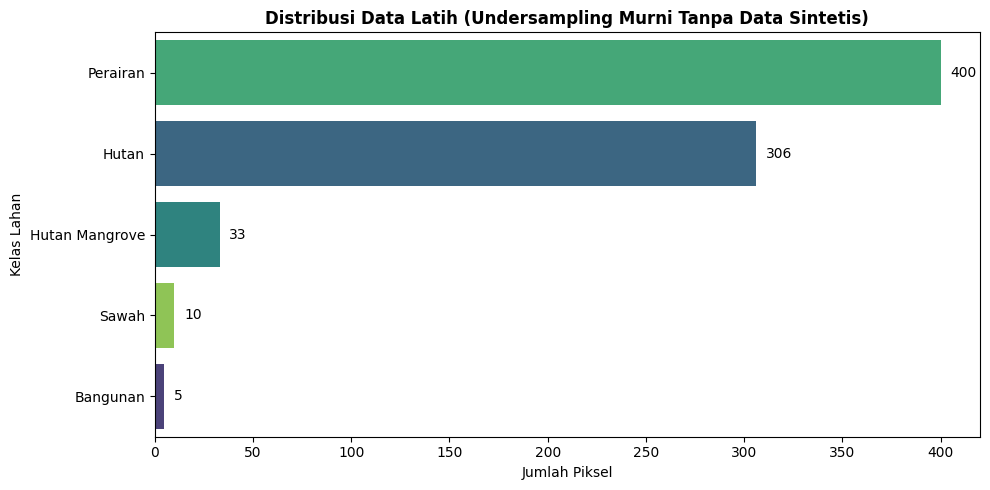

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

df = pd.read_csv('dataset_training.csv').dropna()

# Pemisahan fitur spektral dan variabel target
X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Distribusi Data Latih (Sebelum Balancing):")
print(y_train.value_counts())

# TAHAP BALANCING (Undersampling Murni Tanpa Data Sintetis)
# Kita potong Perairan menjadi 400 agar seimbang dengan Hutan, sisanya biarkan natural
under_strategy = {'Perairan': 400}
under_sampler = RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)
X_train_bal, y_train_bal = under_sampler.fit_resample(X_train, y_train)

print("\nDistribusi Data Latih :")
print(y_train_bal.value_counts())

# Visualisasi Hasil Balancing
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    y=y_train_bal, 
    palette='viridis', 
    order=y_train_bal.value_counts().index,
    hue=y_train_bal,
    legend=False
)
plt.title('Distribusi Data Latih (Undersampling Murni Tanpa Data Sintetis)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + 5, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()


## Modeling

Tahap ini merupakan inti dari seluruh proses pengembangan, di mana algoritma komputer dilatih menggunakan data spektral yang telah disiapkan agar mampu mengenali karakteristik unik permukaan bumi dan melakukan klasifikasi tutupan lahan secara otomatis.

### Konsep Alur Kerja Pemodelan

Proses pemodelan dibagi menjadi dua fase utama untuk memastikan model yang dihasilkan tidak hanya pintar di data latihan, melainkan juga andal saat diuji dengan data baru:
- Fase Pelatihan (Training): Algoritma Random Forest Classifier dilatih menggunakan data latih hasil penyeimbangan hibrida (hybrid balancing). Di tahap ini, model mempelajari pola dan karakteristik unik dari nilai pantulan spektral Band 2, Band 3, Band 4, Band 8a, dan Band 11 untuk masing-masing target kelas objek.
- Fase Pengujian (Testing): Model yang telah selesai dilatih kemudian dievaluasi menggunakan data uji. Data uji ini sengaja disembunyikan sejak awal dan belum pernah dilihat oleh model selama masa pelatihan. Langkah ini krusial untuk menguji performa objektif model saat dihadapkan pada skenario data dunia nyata yang sesungguhnya.



### Rincian Data Latih dan Uji

Sebelum proses pelatihan dimulai, penting untuk meninjau kembali rincian dimensi, struktur, serta distribusi kelas dari data latih yang telah diseimbangkan dan data uji yang akan digunakan sebagai validator performa model.

In [23]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Menampilkan informasi dimensi data
print("Dimensi Dataset Pemodelan:")
print(f"Jumlah sampel data latih : {X_train_bal.shape[0]:,}")
print(f"Jumlah sampel data uji   : {X_test.shape[0]:,}")
print(f"Jumlah fitur spektral    : {X_train_bal.shape[1]} (B2, B3, B4, Band_8a, B11)\n")

print("Komposisi Kelas Data Latih:")
print(y_train_bal.value_counts())

print("\nSamples Data Latih:")
display(X_train_bal.head())


Dimensi Dataset Pemodelan:
Jumlah sampel data latih : 754
Jumlah sampel data uji   : 847
Jumlah fitur spektral    : 5 (B2, B3, B4, Band_8a, B11)

Komposisi Kelas Data Latih:
Class
Perairan          400
Hutan             306
Hutan Mangrove     33
Sawah              10
Bangunan            5
Name: count, dtype: int64

Samples Data Latih:


,Band_2,Band_3,Band_4,Band_8A,Band_11
4229,926.733333,1181.050000,1640.923077,2462.625000,3284.333333
4226,1181.916667,1278.769231,1435.333333,2016.000000,2612.250000
4225,1472.404762,1630.600000,1832.100000,2399.133333,3061.800000
4227,1053.444444,1314.384615,1438.615385,2715.083333,2955.571429
4230,1118.785714,1439.428571,1826.555556,2905.285714,3246.166667



### Proses Pelatihan Model (Training)

Pada tahap ini, algoritma Random Forest diinisialisasi untuk mempelajari hubungan antara karakteristik spektral band satelit dengan kelas tutupan lahan pada data latih. Konfigurasi model menggunakan beberapa parameter kunci dengan alasan teknis berikut:

| Parameter | Nilai / Konfigurasi | Alasan Teknis dan Fungsi |
|---|---|---|
| **n_estimators** | `100` | Membangun 100 pohon keputusan (*decision trees*) secara paralel. Jumlah ini merupakan titik optimal (*sweet spot*) standar untuk menangkap pola spektral yang kompleks tanpa membebani memori komputasi secara berlebihan. |
| **random_state** | `42` | Berfungsi sebagai kunci pengunci keacakan (*seed*). Parameter ini memastikan hasil pengacakan sampel data akan selalu konsisten setiap kali kode dijalankan ulang (*reproducible*). |
| **n_jobs** | `-1` | Memerintahkan komputer untuk menggunakan seluruh inti prosesor (*CPU cores*) secara maksimal untuk mempercepat waktu pelatihan model. |


In [24]:
from sklearn.ensemble import RandomForestClassifier

print("Memulai proses pelatihan model Random Forest...")

# Inisialisasi model dengan Algorithmic Class Weighting (Pengganti SMOTE)
rf_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=10,             # Dibatasi agar tidak overfit pada data kelas minoritas
    min_samples_leaf=2,       # Disesuaikan (tidak terlalu besar) karena data minoritas sangat kecil
    class_weight='balanced',  # WAJIB ADA: Bobot otomatis agar model adil pada Bangunan & Sawah
    random_state=42, 
    n_jobs=-1
)

# Pelatihan model menggunakan data hasil Undersampling Murni
rf_model.fit(X_train_bal, y_train_bal)

print("Proses pelatihan selesai. Model berhasil dibangun.")

Memulai proses pelatihan model Random Forest...
Proses pelatihan selesai. Model berhasil dibangun.


### MODEL
Setelah dilakukannya training, didapatkanlah model seperti berikut :

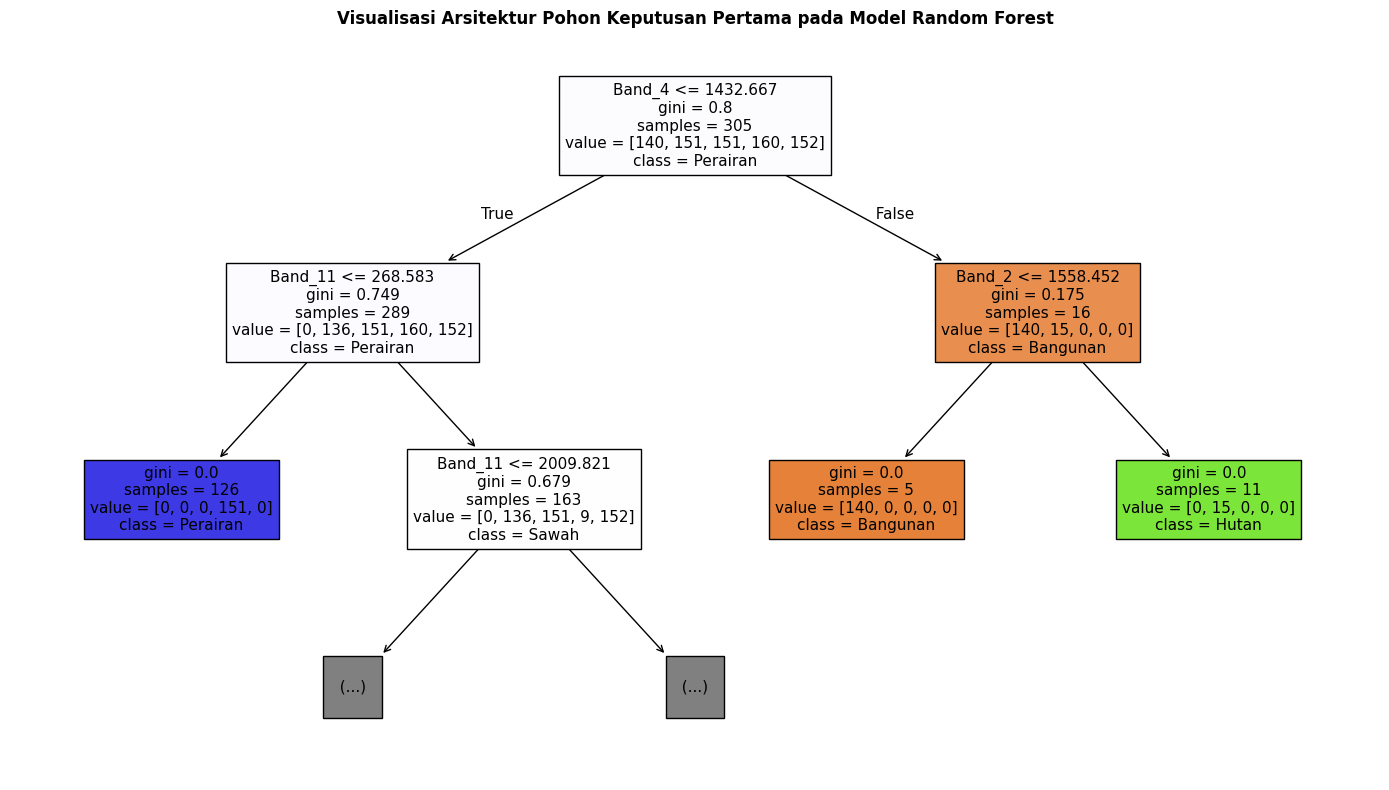

In [25]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Mengekstrak estimator pohon keputusan pertama dari ansambel Random Forest
pohon_pertama = rf_model.estimators_[0]

plt.figure(figsize=(14, 8))
plot_tree(
    pohon_pertama, 
    feature_names=['Band_2', 'Band_3', 'Band_4', 'B8A', 'Band_11'], 
    class_names=list(rf_model.classes_), # Dibungkus list() untuk memastikan formatnya sesuai standar matplotlib
    filled=True, 
    max_depth=2
) 

plt.title("Visualisasi Arsitektur Pohon Keputusan Pertama pada Model Random Forest", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### Pengujian dan Evaluasi Model

Setelah proses pelatihan selesai, model diuji menggunakan data uji untuk mengevaluasi performa klasifikasinya secara menyeluruh. Pengujian ini penting untuk melihat kemampuan generalisasi model terhadap data baru yang belum pernah dipelajari sebelumnya.

Menjalankan prediksi pada data uji...

Akurasi Global Model: 97.76% 

Laporan Klasifikasi Detail:
                precision    recall  f1-score   support

      Bangunan       1.00      1.00      1.00         1
         Hutan       1.00      1.00      1.00        77
Hutan Mangrove       0.30      1.00      0.46         8
      Perairan       1.00      0.97      0.99       759
         Sawah       1.00      1.00      1.00         2

      accuracy                           0.98       847
     macro avg       0.86      0.99      0.89       847
  weighted avg       0.99      0.98      0.98       847



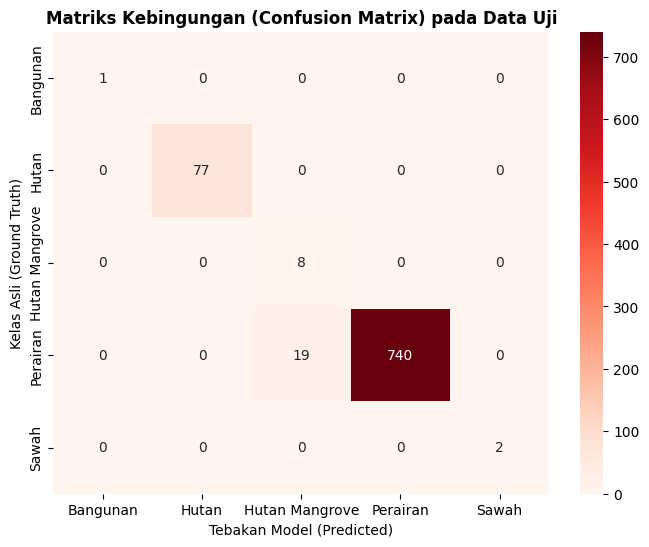


Proses selesai. Model berhasil disimpan sebagai 'model_rf.pkl'


In [30]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

print("Menjalankan prediksi pada data uji...")
# Evaluasi model menggunakan data uji murni yang independen dari proses latih
y_pred = rf_model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)

print(f"\nAkurasi Global Model: {akurasi * 100:.2f}% ")
print("\nLaporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred))

# Membongkar salah tebak model dengan Matriks Kebingungan
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=rf_model.classes_, 
            yticklabels=rf_model.classes_)
plt.title('Matriks Kebingungan (Confusion Matrix) pada Data Uji', fontweight='bold')
plt.ylabel('Kelas Asli (Ground Truth)')
plt.xlabel('Tebakan Model (Predicted)')
plt.show()

# Ekspor hasil pemodelan ke berkas biner pkl
joblib.dump(rf_model, 'model_rf.pkl')
print("\nProses selesai. Model berhasil disimpan sebagai 'model_rf.pkl'")

## DEPLOYMENT


In [31]:
import os
import rasterio
import numpy as np
import joblib

input_tif = 'Sentinel2_Area.tif'
output_tif = 'Hasil_Klasifikasi_LULC.tif'
file_model = 'model_rf.pkl'

if os.path.exists(output_tif):
    print(f"File output '{output_tif}' sudah tersedia. Proses inferensi raster dilewati.")
else:
    print(f"Memuat model Random Forest dari '{file_model}'...")
    rf_model = joblib.load(file_model) 

    print("Membuka citra satelit input...")
    with rasterio.open(input_tif) as src:
        meta = src.meta
        # Membaca 5 Band (B2, B3, B4, Band_8a, B11) secara berurutan sesuai urutan fitur data latih
        img_data = src.read([1, 2, 3, 4, 5]) 
        print(f"Dimensi citra input: {img_data.shape} (Band, Baris, Kolom)")

    # Transformasi matriks 3D menjadi format tabel tabular (2D) untuk input model
    n_bands, baris, kolom = img_data.shape
    img_flatten = img_data.reshape(n_bands, -1).T 

    # Masking piksel background bernilai 0 di luar area kajian
    mask = (img_flatten[:, 0] > 0)
    data_valid = img_flatten[mask]

    print(f"Melakukan klasifikasi pada {data_valid.shape[0]:,} piksel data valid...")
    prediksi_valid = rf_model.predict(data_valid)

    print("Proses klasifikasi selesai. Melakukan pemetaan ulang nilai spektral...")

    # Konversi label kategori string menjadi nilai integer biner untuk format raster GeoTIFF
    kamus_warna = {
        'Perairan': 1,
        'Hutan': 2,
        'Hutan Mangrove': 3,
        'Sawah': 4,
        'Bangunan': 5
    }
    prediksi_angka = np.vectorize(kamus_warna.get)(prediksi_valid)

    # Rekonstruksi bentuk data kembali ke dimensi spasial asli (Baris x Kolom)
    peta_hasil = np.zeros(baris * kolom, dtype=np.uint8)
    peta_hasil[mask] = prediksi_angka
    peta_hasil_2d = peta_hasil.reshape(baris, kolom)

    # Pembaruan metadata file output (1 Band, Format UInt8, NoData = 0)
    meta.update(count=1, dtype=rasterio.uint8, nodata=0) 

    print("Menulis file output raster...")
    with rasterio.open(output_tif, 'w', **meta) as dst:
        dst.write(peta_hasil_2d, 1)

    print(f"Proses selesai. File klasifikasi spasial disimpan di: {output_tif}")


Memuat model Random Forest dari 'model_rf.pkl'...
Membuka citra satelit input...
Dimensi citra input: (5, 2055, 3336) (Band, Baris, Kolom)
Melakukan klasifikasi pada 6,855,477 piksel data valid...


C:\Users\mappattiro\kal\kal\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Proses klasifikasi selesai. Melakukan pemetaan ulang nilai spektral...
Menulis file output raster...
Proses selesai. File klasifikasi spasial disimpan di: Hasil_Klasifikasi_LULC.tif


### HASIL STREAMLIT

Untuk melihat hasil pemetaan, masuk ke link berikut :
https://lulc-jatim-app-uts.streamlit.app/